# Self-Reflective AI Assistant for Crop Disease Diagnosis

## PBL-3 — Presentation 1 Prototype

This notebook extends the established crop-disease classification baseline toward a self-reflection mechanism.

The prototype evaluates whether a model's prediction should be trusted using three measurable signals:
- prediction confidence,
- predictive entropy, and
- feature-space familiarity.

Grad-CAM is additionally used as qualitative visual evidence.

**Scope:** PBL-3 Presentation 1. The reflection rule and thresholds shown here are provisional prototype choices; formal threshold selection and comparative evaluation are reserved for the next evaluation phase.


## 1. Imports and Dependencies


In [ ]:
import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import normalize
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from pytorch_grad_cam import GuidedBackpropReLUModel, GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


## 2. Computational Environment


In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


PyTorch: 2.14.0+cu130
CUDA: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 3060


## 3. Dataset Configuration


In [ ]:
# Repository-relative dataset location.
# The dataset is not included in version control.
dataset_path = Path("../data/PlantVillage")

RESULTS_DIR = Path("../results")
MODELS_DIR = Path("../models")
RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)


### 3.1 Class Inspection


In [4]:
classes = sorted([p.name for p in dataset_path.iterdir() if p.is_dir()])

for i, cls in enumerate(classes):
    print(i, cls)

0 Pepper__bell___Bacterial_spot
1 Pepper__bell___healthy
2 Potato___Early_blight
3 Potato___Late_blight
4 Potato___healthy
5 Tomato_Bacterial_spot
6 Tomato_Early_blight
7 Tomato_Late_blight
8 Tomato_Leaf_Mold
9 Tomato_Septoria_leaf_spot
10 Tomato_Spider_mites_Two_spotted_spider_mite
11 Tomato__Target_Spot
12 Tomato__Tomato_YellowLeaf__Curl_Virus
13 Tomato__Tomato_mosaic_virus
14 Tomato_healthy


### 3.2 Image Preprocessing and Dataset Loading


In [9]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

dataset = datasets.ImageFolder(dataset_path, transform=transform)
num_classes = len(dataset.classes)

print("Total images:", len(dataset))
print("Number of classes:", num_classes)


20638
15


## 4. Stratified 3-Fold Cross-Validation


Stratified 3-fold cross-validation is used to obtain out-of-fold (OOF) predictions.

Each image is evaluated using a fold-specific model that did not use that image for training. These OOF predictions are subsequently used by the reflection prototype.


In [10]:
kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

fold_results = []


### 4.1 Out-of-Fold Prediction Storage


In [11]:
oof_logits = np.zeros((len(dataset), num_classes))
oof_labels = np.array(dataset.targets)
oof_predictions = np.zeros(len(dataset), dtype=int)
oof_folds = np.zeros(len(dataset), dtype=int)

## 5. Baseline Model Training


**Model:** ImageNet-pretrained MobileNetV3-Small.

The feature extractor is frozen and only the final classifier layer is retrained for the 15 crop-disease classes.


===== Fold 1 =====
Fold 1, Epoch 1, Loss: 332.1499
Fold 1, Epoch 2, Loss: 154.0825
Fold 1, Epoch 3, Loss: 125.4674
Fold 1, Epoch 4, Loss: 108.9472
Fold 1, Epoch 5, Loss: 95.8538
Fold 1, Epoch 6, Loss: 89.7494
Fold 1, Epoch 7, Loss: 84.5329
Fold 1, Epoch 8, Loss: 79.4426
Fold 1, Epoch 9, Loss: 77.6550
Fold 1, Epoch 10, Loss: 73.2668
Fold 1 Accuracy: 93.28%

===== Fold 2 =====
Fold 2, Epoch 1, Loss: 336.0487
Fold 2, Epoch 2, Loss: 156.4096
Fold 2, Epoch 3, Loss: 123.0703
Fold 2, Epoch 4, Loss: 106.6574
Fold 2, Epoch 5, Loss: 97.0071
Fold 2, Epoch 6, Loss: 91.0676
Fold 2, Epoch 7, Loss: 87.3733
Fold 2, Epoch 8, Loss: 79.3660
Fold 2, Epoch 9, Loss: 74.4551
Fold 2, Epoch 10, Loss: 72.8719
Fold 2 Accuracy: 93.43%

===== Fold 3 =====
Fold 3, Epoch 1, Loss: 334.1419
Fold 3, Epoch 2, Loss: 152.8982
Fold 3, Epoch 3, Loss: 122.6699
Fold 3, Epoch 4, Loss: 105.8509
Fold 3, Epoch 5, Loss: 94.1100
Fold 3, Epoch 6, Loss: 88.9746
Fold 3, Epoch 7, Loss: 83.8772
Fold 3, Epoch 8, Loss: 80.9337
Fold 3, Ep

<Figure size 1200x1200 with 0 Axes>

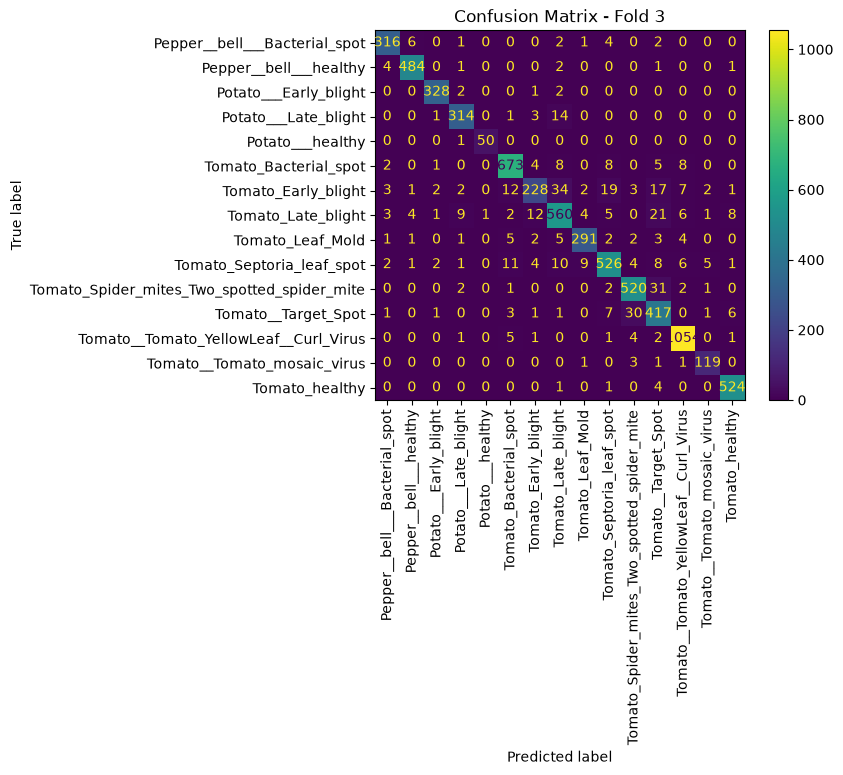

In [14]:
best_accuracy = 0
best_model = None
best_fold = None

for fold, (train_idx, val_idx) in enumerate(
    kf.split(np.zeros(len(dataset)), dataset.targets)
):
    print(f"\n===== Fold {fold+1} =====")

    train_dataset = Subset(dataset, train_idx)
    val_dataset = Subset(dataset, val_idx)

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

    model = models.mobilenet_v3_small(weights="DEFAULT")

    for param in model.parameters():
        param.requires_grad = False

    model.classifier[3] = nn.Linear(
        model.classifier[3].in_features,
        num_classes
    )

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.classifier[3].parameters(), lr=0.001)

    epochs = 10

    for epoch in range(epochs):
        model.train()
        running_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(
            f"Fold {fold+1}, Epoch {epoch+1}, "
            f"Loss: {running_loss:.4f}"
        )

    model.eval()
    all_preds = []
    all_labels = []
    correct = 0
    total = 0
    val_position = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            batch_size = labels.size(0)
            batch_indices = val_idx[
                val_position:val_position + batch_size
            ]

            oof_logits[batch_indices] = outputs.cpu().numpy()
            oof_predictions[batch_indices] = predicted.cpu().numpy()
            oof_folds[batch_indices] = fold + 1

            val_position += batch_size

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    fold_results.append(accuracy)

    if fold == 2:
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(12, 12))
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=dataset.classes
        )
        disp.plot(xticks_rotation=90)
        plt.title(f"Confusion Matrix - Fold {fold+1}")
        plt.savefig(
            RESULTS_DIR / "confusion_matrix.png",
            bbox_inches="tight"
        )
        plt.show()

    print(f"Fold {fold+1} Accuracy: {accuracy:.2f}%")

    torch.save(
        model.state_dict(),
        MODELS_DIR / f"mobilenet_fold_{fold+1}.pth"
    )

    if fold == 0 or accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = model
        best_fold = fold + 1

        torch.save(
            model.state_dict(),
            MODELS_DIR / "best_model.pth"
        )

        sample_images = images
        sample_labels = labels


### 5.1 Fold-3 Result Recovery


The following cell records the recovered Fold-3 accuracy from the OOF predictions after the prototype training cell stopped before printing the final Fold-3 accuracy.


### 5.1 Baseline Cross-Validation Results


In [21]:
# Recorded fold accuracies from the completed prototype run.
fold_results = [
    93.28488372093024,
    93.42927751126618,
    93.09492658816689
]

print("Fold Accuracies:", fold_results)
print("Mean Accuracy:", np.mean(fold_results))
print("Std Dev:", np.std(fold_results))


Fold Accuracies: [93.28488372093024, 93.42927751126618, 93.09492658816689]
Mean Accuracy: 93.2696959401211
Std Dev: 0.13692001669774767


### 5.2 OOF Prediction Verification


In [17]:
print("OOF logits shape:", oof_logits.shape)
print("OOF labels shape:", oof_labels.shape)
print("OOF predictions shape:", oof_predictions.shape)
print("Unique folds:", np.unique(oof_folds))

OOF logits shape: (20638, 15)
OOF labels shape: (20638,)
OOF predictions shape: (20638,)
Unique folds: [1 2 3]


## 6. Self-Reflection Prototype


A top-1 prediction identifies the most likely class, but does not by itself establish reliability.

The prototype therefore evaluates multiple internal signals:

\[
R(x)=g(C,H,S,E)
\]

where:
- \(C\) = prediction confidence,
- \(H\) = predictive entropy,
- \(S\) = feature-space familiarity,
- \(E\) = explanation evidence.

The current numerical decision rule uses \(C\), \(H\), and \(S\). Grad-CAM is used later as qualitative evidence for \(E\).


### 6.1 Prediction Confidence


In [18]:
oof_probabilities = torch.softmax(
    torch.tensor(oof_logits),
    dim=1
).numpy()

oof_confidence = np.max(oof_probabilities, axis=1)

print("Confidence shape:", oof_confidence.shape)
print("Minimum confidence:", oof_confidence.min())
print("Maximum confidence:", oof_confidence.max())
print("Mean confidence:", oof_confidence.mean())

Confidence shape: (20638,)
Minimum confidence: 0.21633261721272234
Maximum confidence: 0.9999999951130183
Mean confidence: 0.9249763854756696


### 6.2 Predictive Entropy


In [23]:
# Calculate predictive entropy

oof_entropy = -np.sum(
    oof_probabilities * np.log(oof_probabilities + 1e-12),
    axis=1
)

# Normalize entropy to [0, 1]
oof_entropy_normalized = oof_entropy / np.log(num_classes)

print("Entropy shape:", oof_entropy.shape)
print("Minimum entropy:", oof_entropy.min())
print("Maximum entropy:", oof_entropy.max())
print("Mean entropy:", oof_entropy.mean())

print("\nNormalized entropy:")
print("Minimum:", oof_entropy_normalized.min())
print("Maximum:", oof_entropy_normalized.max())
print("Mean:", oof_entropy_normalized.mean())

Entropy shape: (20638,)
Minimum entropy: 1.0568195315587261e-07
Maximum entropy: 2.1508244080493943
Mean entropy: 0.22914513997388566

Normalized entropy:
Minimum: 3.9025108586561186e-08
Maximum: 0.7942335807415911
Mean: 0.08461628217993179


### 6.3 Fold Model Checkpoints


In [28]:
# Prepare the fold-specific MobileNetV3-Small models used for OOF feature extraction.

fold_models = []

for fold in range(1, 4):
    fold_model = models.mobilenet_v3_small(weights=None)

    fold_model.classifier[3] = nn.Linear(
        fold_model.classifier[3].in_features,
        num_classes
    )

    fold_model.load_state_dict(
        torch.load(
            MODELS_DIR / f"mobilenet_fold_{fold}.pth",
            map_location=device
        )
    )

    fold_model = fold_model.to(device)
    fold_model.eval()

    fold_models.append(fold_model)

print(f"Loaded {len(fold_models)} fold models.")


Loaded 3 fold models.


### 6.4 Feature-Space Representation and Familiarity


In [29]:
# Extract feature embeddings for all OOF samples

oof_embeddings = np.zeros((len(dataset), 576))

for fold in range(1, 4):

    fold_mask = (oof_folds == fold)
    fold_indices = np.where(fold_mask)[0]

    fold_model = fold_models[fold - 1]

    fold_subset = Subset(dataset, fold_indices)

    fold_loader = DataLoader(
        fold_subset,
        batch_size=32,
        shuffle=False
    )

    embeddings = []

    with torch.no_grad():
        for images, _ in fold_loader:

            images = images.to(device)

            features = fold_model.features(images)

            features = fold_model.avgpool(features)

            features = torch.flatten(features, 1)

            embeddings.append(features.cpu().numpy())

    embeddings = np.concatenate(embeddings, axis=0)

    oof_embeddings[fold_indices] = embeddings

    print(
        f"Fold {fold}: extracted embeddings for "
        f"{len(fold_indices)} samples"
    )

print("OOF embedding shape:", oof_embeddings.shape)

Fold 1: extracted embeddings for 6880 samples
Fold 2: extracted embeddings for 6879 samples
Fold 3: extracted embeddings for 6879 samples
OOF embedding shape: (20638, 576)


In [30]:

# Store familiarity scores for every OOF sample
oof_familiarity = np.zeros(len(dataset))

for fold in range(1, 4):

    # Samples belonging to this fold's validation set
    val_mask = (oof_folds == fold)
    val_indices = np.where(val_mask)[0]

    # Samples belonging to the other folds
    train_mask = ~val_mask
    train_indices = np.where(train_mask)[0]

    # Build class prototypes using only training samples
    class_prototypes = np.zeros((num_classes, oof_embeddings.shape[1]))

    for class_id in range(num_classes):

        class_mask = (
            oof_labels[train_indices] == class_id
        )

        class_indices = train_indices[class_mask]

        class_prototypes[class_id] = np.mean(
            oof_embeddings[class_indices],
            axis=0
        )

    # Normalize embeddings and prototypes
    normalized_prototypes = normalize(class_prototypes)

    normalized_validation = normalize(
        oof_embeddings[val_indices]
    )

    # Cosine similarity to every class prototype
    similarities = normalized_validation @ normalized_prototypes.T

    # Select similarity to the model's predicted class
    predicted_classes = oof_predictions[val_indices]

    oof_familiarity[val_indices] = similarities[
        np.arange(len(val_indices)),
        predicted_classes
    ]

    print(
        f"Fold {fold}: calculated familiarity for "
        f"{len(val_indices)} samples"
    )

print("\nFamiliarity shape:", oof_familiarity.shape)
print("Minimum familiarity:", oof_familiarity.min())
print("Maximum familiarity:", oof_familiarity.max())
print("Mean familiarity:", oof_familiarity.mean())


Fold 1: calculated familiarity for 6880 samples
Fold 2: calculated familiarity for 6879 samples
Fold 3: calculated familiarity for 6879 samples

Familiarity shape: (20638,)
Minimum familiarity: 0.049900214486443176
Maximum familiarity: 0.9213475979731076
Mean familiarity: 0.7865490399105783


### 6.5 Correct vs. Incorrect Prediction Analysis


In [31]:
# Identify correct and incorrect OOF predictions

oof_correct = (
    oof_predictions == oof_labels
)

print("Correct predictions:", np.sum(oof_correct))
print("Incorrect predictions:", np.sum(~oof_correct))
print(
    "Overall accuracy:",
    np.mean(oof_correct) * 100
)

print("\n--- Confidence ---")
print(
    "Correct mean:",
    oof_confidence[oof_correct].mean()
)
print(
    "Incorrect mean:",
    oof_confidence[~oof_correct].mean()
)

print("\n--- Normalized Entropy ---")
print(
    "Correct mean:",
    oof_entropy_normalized[oof_correct].mean()
)
print(
    "Incorrect mean:",
    oof_entropy_normalized[~oof_correct].mean()
)

print("\n--- Familiarity ---")
print(
    "Correct mean:",
    oof_familiarity[oof_correct].mean()
)
print(
    "Incorrect mean:",
    oof_familiarity[~oof_correct].mean()
)

Correct predictions: 19249
Incorrect predictions: 1389
Overall accuracy: 93.2696966760345

--- Confidence ---
Correct mean: 0.9448903410120779
Incorrect mean: 0.6490053774696765

--- Normalized Entropy ---
Correct mean: 0.06705236106173232
Incorrect mean: 0.32802011054870195

--- Familiarity ---
Correct mean: 0.7900769159453219
Incorrect mean: 0.7376591293326227


### 6.6 Reflection Signal Distributions


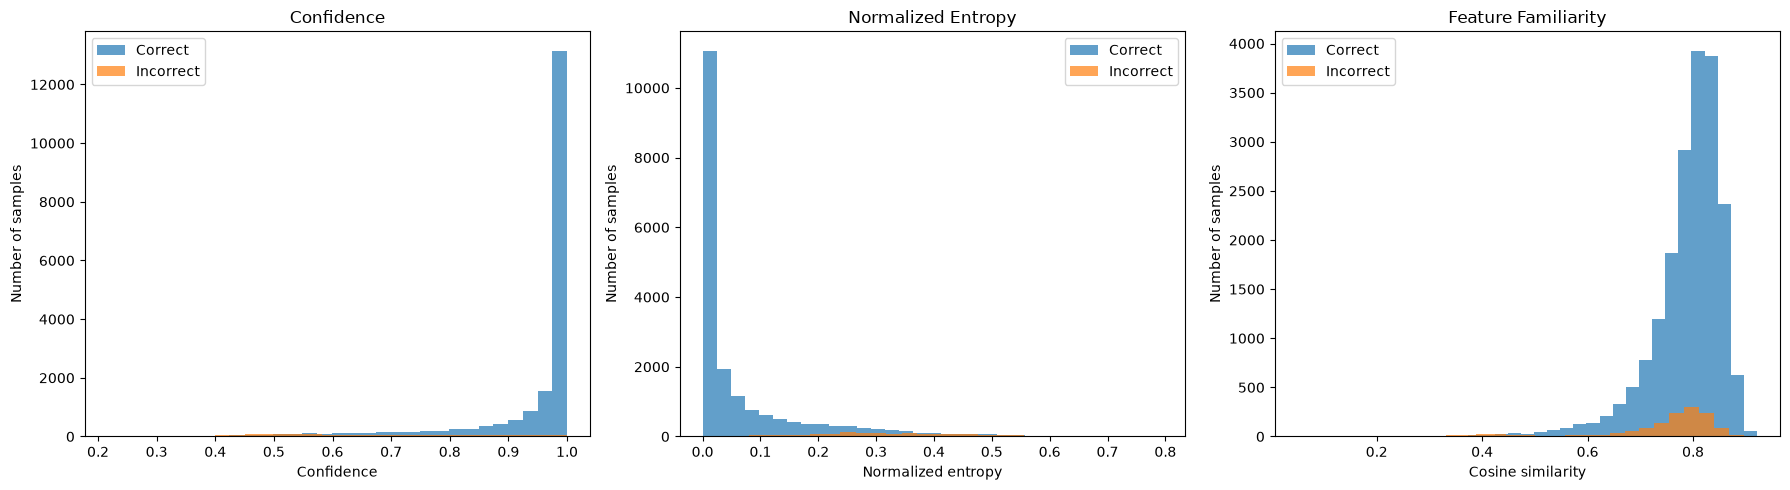

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confidence
axes[0].hist(
    oof_confidence[oof_correct],
    bins=30,
    alpha=0.7,
    label="Correct"
)
axes[0].hist(
    oof_confidence[~oof_correct],
    bins=30,
    alpha=0.7,
    label="Incorrect"
)
axes[0].set_title("Confidence")
axes[0].set_xlabel("Confidence")
axes[0].set_ylabel("Number of samples")
axes[0].legend()

# Normalized entropy
axes[1].hist(
    oof_entropy_normalized[oof_correct],
    bins=30,
    alpha=0.7,
    label="Correct"
)
axes[1].hist(
    oof_entropy_normalized[~oof_correct],
    bins=30,
    alpha=0.7,
    label="Incorrect"
)
axes[1].set_title("Normalized Entropy")
axes[1].set_xlabel("Normalized entropy")
axes[1].set_ylabel("Number of samples")
axes[1].legend()

# Familiarity
axes[2].hist(
    oof_familiarity[oof_correct],
    bins=30,
    alpha=0.7,
    label="Correct"
)
axes[2].hist(
    oof_familiarity[~oof_correct],
    bins=30,
    alpha=0.7,
    label="Incorrect"
)
axes[2].set_title("Feature Familiarity")
axes[2].set_xlabel("Cosine similarity")
axes[2].set_ylabel("Number of samples")
axes[2].legend()

plt.tight_layout()
plt.show()

### 6.7 Signal Percentile Inspection


In [33]:
# Inspect signal percentiles for correct and incorrect predictions

for name, correct_values, incorrect_values in [
    ("Confidence", oof_confidence[oof_correct], oof_confidence[~oof_correct]),
    ("Normalized Entropy", oof_entropy_normalized[oof_correct], oof_entropy_normalized[~oof_correct]),
    ("Familiarity", oof_familiarity[oof_correct], oof_familiarity[~oof_correct])
]:
    print(f"\n{name}")
    print("Correct percentiles:")
    print(np.percentile(correct_values, [10, 25, 50, 75, 90]))
    print("Incorrect percentiles:")
    print(np.percentile(incorrect_values, [10, 25, 50, 75, 90]))


Confidence
Correct percentiles:
[0.81109263 0.95583212 0.99455123 0.99944686 0.99992772]
Incorrect percentiles:
[0.41277553 0.50039097 0.63216248 0.80193614 0.92370606]

Normalized Entropy
Correct percentiles:
[0.00030968 0.00194076 0.01432321 0.08008377 0.2274369 ]
Incorrect percentiles:
[0.124636   0.22757676 0.31766611 0.43151633 0.53564646]

Familiarity
Correct percentiles:
[0.70811369 0.76421382 0.80478787 0.83516461 0.85581903]
Incorrect percentiles:
[0.56817205 0.72354089 0.77832023 0.81124806 0.83434222]


### 6.8 Provisional Reflection Rule

The following thresholds are intentionally provisional for Presentation 1. They were chosen after inspecting the available OOF signal distributions, so the resulting reflection statistics are **prototype diagnostics, not final leakage-free evaluation metrics**.


In [34]:
# Provisional thresholds for the Presentation 1 reflection prototype

CONFIDENCE_THRESHOLD = 0.80
ENTROPY_THRESHOLD = 0.20
FAMILIARITY_THRESHOLD = 0.75

low_confidence = oof_confidence < CONFIDENCE_THRESHOLD
high_entropy = oof_entropy_normalized > ENTROPY_THRESHOLD
low_familiarity = oof_familiarity < FAMILIARITY_THRESHOLD

# Reflection is triggered if any reliability signal is concerning
oof_reflection_flag = (
    low_confidence |
    high_entropy |
    low_familiarity
)

print("Total samples:", len(oof_reflection_flag))
print("Reflection flagged:", np.sum(oof_reflection_flag))
print(
    "Reflection rate:",
    np.mean(oof_reflection_flag) * 100,
    "%"
)

print("\nIndividual signals:")
print("Low confidence:", np.sum(low_confidence))
print("High entropy:", np.sum(high_entropy))
print("Low familiarity:", np.sum(low_familiarity))

Total samples: 20638
Reflection flagged: 6574
Reflection rate: 31.85386180831476 %

Individual signals:
Low confidence: 2853
High entropy: 3416
Low familiarity: 4264


### 6.9 Prototype Reflection Evaluation


In [35]:
# Evaluate how well the reflection flag identifies incorrect predictions

incorrect = ~oof_correct

true_errors_caught = np.sum(
    oof_reflection_flag & incorrect
)

errors_missed = np.sum(
    ~oof_reflection_flag & incorrect
)

correct_flagged = np.sum(
    oof_reflection_flag & oof_correct
)

correct_accepted = np.sum(
    ~oof_reflection_flag & oof_correct
)

print("Incorrect predictions:", np.sum(incorrect))
print("Incorrect predictions flagged:", true_errors_caught)
print("Incorrect predictions missed:", errors_missed)

print("\nCorrect predictions:", np.sum(oof_correct))
print("Correct predictions flagged:", correct_flagged)
print("Correct predictions accepted:", correct_accepted)

print("\n--- Reflection Statistics ---")

error_detection_rate = (
    true_errors_caught / np.sum(incorrect) * 100
)

false_reflection_rate = (
    correct_flagged / np.sum(oof_correct) * 100
)

print(
    f"Error Detection Rate: "
    f"{error_detection_rate:.2f}%"
)

print(
    f"False Reflection Rate: "
    f"{false_reflection_rate:.2f}%"
)

Incorrect predictions: 1389
Incorrect predictions flagged: 1203
Incorrect predictions missed: 186

Correct predictions: 19249
Correct predictions flagged: 5371
Correct predictions accepted: 13878

--- Reflection Statistics ---
Error Detection Rate: 86.61%
False Reflection Rate: 27.90%


## 7. Reflection Demonstration


In [36]:
# Select representative samples for the reflection demonstration

accepted_correct_indices = np.where(
    oof_correct & ~oof_reflection_flag
)[0]

flagged_incorrect_indices = np.where(
    ~oof_correct & oof_reflection_flag
)[0]

correct_sample_idx = accepted_correct_indices[0]
incorrect_sample_idx = flagged_incorrect_indices[0]

print("Correct + Accepted sample:", correct_sample_idx)
print("Incorrect + Flagged sample:", incorrect_sample_idx)

Correct + Accepted sample: 0
Incorrect + Flagged sample: 59


In [37]:
def inspect_reflection_sample(index):
    print(f"Sample index: {index}")
    print(f"True class:       {dataset.classes[oof_labels[index]]}")
    print(f"Predicted class:  {dataset.classes[oof_predictions[index]]}")
    print(f"Correct:          {oof_correct[index]}")
    print()
    print(f"Confidence:       {oof_confidence[index]:.4f}")
    print(f"Normalized entropy: {oof_entropy_normalized[index]:.4f}")
    print(f"Familiarity:      {oof_familiarity[index]:.4f}")
    print()
    print(f"Low confidence:   {low_confidence[index]}")
    print(f"High entropy:     {high_entropy[index]}")
    print(f"Low familiarity:  {low_familiarity[index]}")
    print()
    print(
        "Reflection decision:",
        "REFLECT" if oof_reflection_flag[index] else "ACCEPT"
    )


print("========== CORRECT + ACCEPTED ==========")
inspect_reflection_sample(correct_sample_idx)

print("\n========== INCORRECT + FLAGGED ==========")
inspect_reflection_sample(incorrect_sample_idx)

========== CORRECT + ACCEPTED ==========
Sample index: 0
True class:       Pepper__bell___Bacterial_spot
Predicted class:  Pepper__bell___Bacterial_spot
Correct:          True

Confidence:       0.9999
Normalized entropy: 0.0003
Familiarity:      0.8319

Low confidence:   False
High entropy:     False
Low familiarity:  False

Reflection decision: ACCEPT

========== INCORRECT + FLAGGED ==========
Sample index: 59
True class:       Pepper__bell___Bacterial_spot
Predicted class:  Pepper__bell___healthy
Correct:          False

Confidence:       0.5308
Normalized entropy: 0.2561
Familiarity:      0.8560

Low confidence:   True
High entropy:     True
Low familiarity:  False

Reflection decision: REFLECT


CORRECT + ACCEPTED


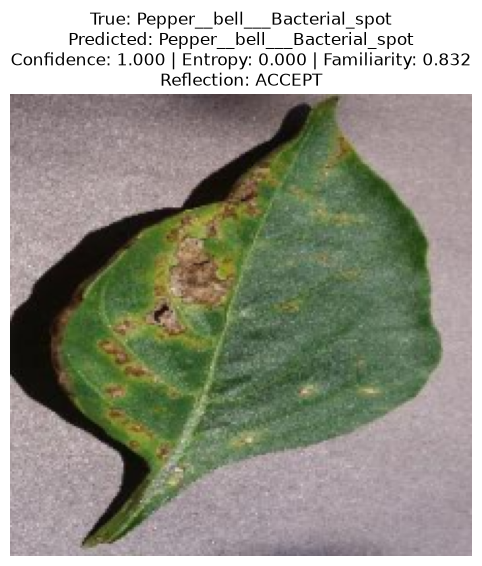

INCORRECT + REFLECTED


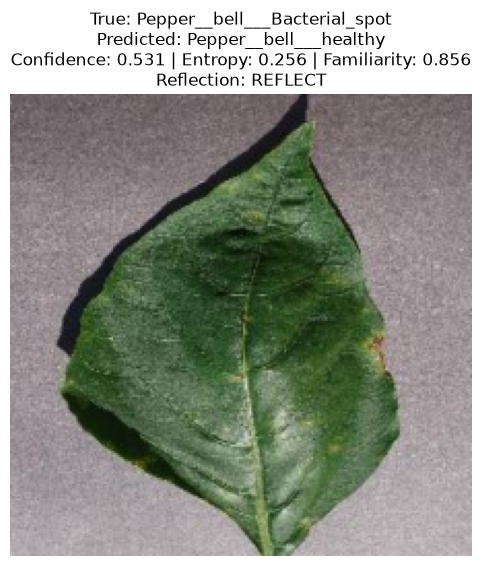

In [38]:
def show_reflection_sample(index):

    image, _ = dataset[index]

    display_img = image.permute(1, 2, 0).cpu().numpy()
    display_img = (display_img * 0.5) + 0.5
    display_img = np.clip(display_img, 0, 1)

    decision = (
        "REFLECT"
        if oof_reflection_flag[index]
        else "ACCEPT"
    )

    plt.figure(figsize=(6, 6))
    plt.imshow(display_img)
    plt.axis("off")

    plt.title(
        f"True: {dataset.classes[oof_labels[index]]}\n"
        f"Predicted: {dataset.classes[oof_predictions[index]]}\n"
        f"Confidence: {oof_confidence[index]:.3f} | "
        f"Entropy: {oof_entropy_normalized[index]:.3f} | "
        f"Familiarity: {oof_familiarity[index]:.3f}\n"
        f"Reflection: {decision}"
    )

    plt.show()


print("CORRECT + ACCEPTED")
show_reflection_sample(correct_sample_idx)

print("INCORRECT + REFLECTED")
show_reflection_sample(incorrect_sample_idx)

In [39]:
def calculate_explanation_focus(model, image_tensor, predicted_class):
    """
    Calculate Grad-CAM explanation focus for one image.

    Higher score = more spatially concentrated activation.
    """

    model.eval()

    # Grad-CAM requires gradients through the target layer
    for param in model.features[12].parameters():
        param.requires_grad = True

    target_layers = [model.features[12][0]]

    cam = GradCAM(
        model=model,
        target_layers=target_layers
    )

    targets = [
        ClassifierOutputTarget(predicted_class)
    ]

    grayscale_cam = cam(
        input_tensor=image_tensor,
        targets=targets
    )[0]

    # Convert CAM into a probability-like spatial distribution
    cam_values = grayscale_cam.astype(np.float64)

    cam_values = cam_values + 1e-12

    cam_distribution = (
        cam_values / np.sum(cam_values)
    )

    # Spatial entropy
    cam_entropy = -np.sum(
        cam_distribution *
        np.log(cam_distribution)
    )

    # Normalize entropy
    num_locations = cam_distribution.size

    normalized_entropy = (
        cam_entropy / np.log(num_locations)
    )

    # Higher = more focused explanation
    explanation_focus = 1 - normalized_entropy

    return grayscale_cam, explanation_focus

In [40]:
def get_explanation_for_sample(index):
    # Identify the fold that produced this sample's OOF prediction
    fold = int(oof_folds[index])

    model = fold_models[fold - 1]

    image, _ = dataset[index]
    image_tensor = image.unsqueeze(0).to(device)

    predicted_class = int(oof_predictions[index])

    grayscale_cam, explanation_focus = calculate_explanation_focus(
        model,
        image_tensor,
        predicted_class
    )

    return image, grayscale_cam, explanation_focus


# Correct + accepted sample
image_correct, cam_correct, focus_correct = (
    get_explanation_for_sample(correct_sample_idx)
)

# Incorrect + reflected sample
image_incorrect, cam_incorrect, focus_incorrect = (
    get_explanation_for_sample(incorrect_sample_idx)
)

print("Correct + Accepted")
print(f"Explanation focus: {focus_correct:.4f}")

print("\nIncorrect + Reflected")
print(f"Explanation focus: {focus_incorrect:.4f}")

Correct + Accepted
Explanation focus: 0.0282

Incorrect + Reflected
Explanation focus: 0.0474


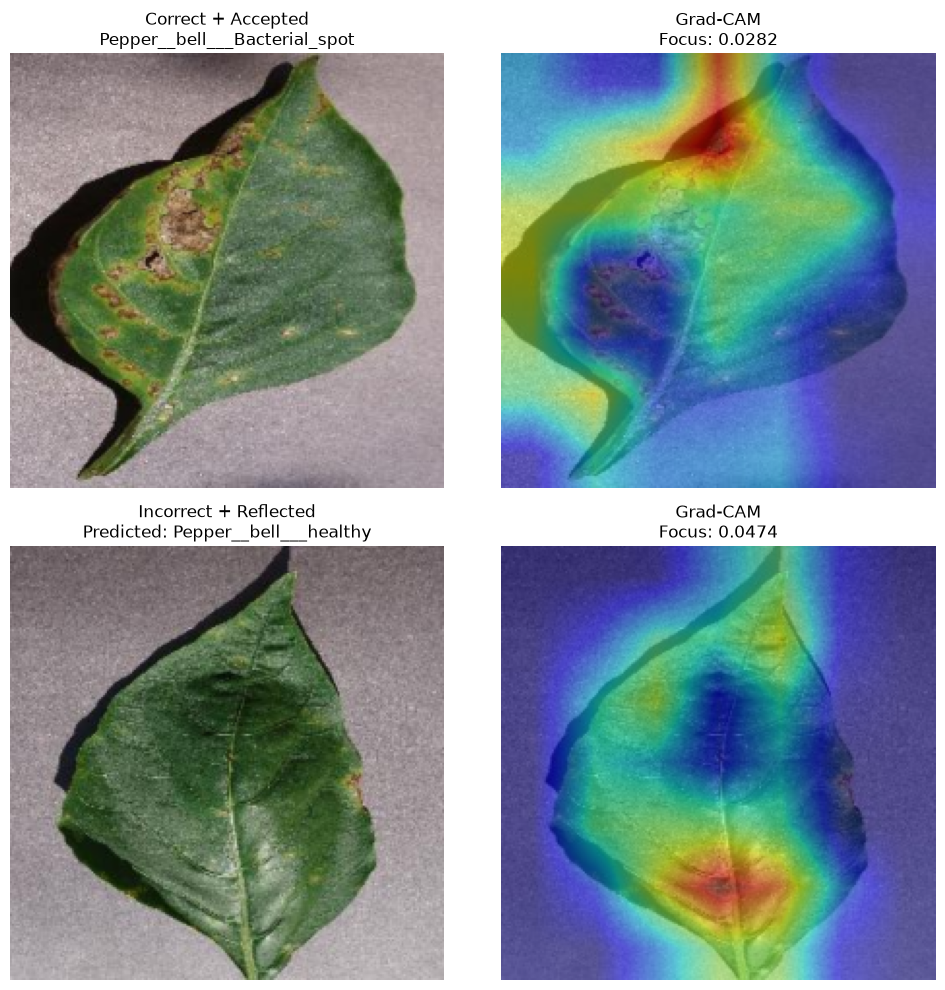

In [41]:
def prepare_display_image(image):
    display_img = image.permute(1, 2, 0).cpu().numpy()
    display_img = (display_img * 0.5) + 0.5
    return np.clip(display_img, 0, 1)


fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# ----- Correct sample -----

display_img = prepare_display_image(image_correct)

axes[0, 0].imshow(display_img)
axes[0, 0].set_title(
    f"Correct + Accepted\n"
    f"{dataset.classes[oof_predictions[correct_sample_idx]]}"
)
axes[0, 0].axis("off")

axes[0, 1].imshow(display_img)
axes[0, 1].imshow(cam_correct, alpha=0.5, cmap="jet")
axes[0, 1].set_title(
    f"Grad-CAM\nFocus: {focus_correct:.4f}"
)
axes[0, 1].axis("off")


# ----- Incorrect sample -----

display_img = prepare_display_image(image_incorrect)

axes[1, 0].imshow(display_img)
axes[1, 0].set_title(
    f"Incorrect + Reflected\n"
    f"Predicted: {dataset.classes[oof_predictions[incorrect_sample_idx]]}"
)
axes[1, 0].axis("off")

axes[1, 1].imshow(display_img)
axes[1, 1].imshow(cam_incorrect, alpha=0.5, cmap="jet")
axes[1, 1].set_title(
    f"Grad-CAM\nFocus: {focus_incorrect:.4f}"
)
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

In [42]:
def create_reflection_record(index):
    return {
        "image_index": int(index),
        "true_class": dataset.classes[oof_labels[index]],
        "predicted_class": dataset.classes[oof_predictions[index]],
        "correct": bool(oof_correct[index]),
        "confidence": float(oof_confidence[index]),
        "normalized_entropy": float(oof_entropy_normalized[index]),
        "familiarity": float(oof_familiarity[index]),
        "explanation_focus": (
            float(focus_correct)
            if index == correct_sample_idx
            else float(focus_incorrect)
            if index == incorrect_sample_idx
            else None
        ),
        "reflection_decision": (
            "REFLECT"
            if oof_reflection_flag[index]
            else "ACCEPT"
        )
    }


correct_record = create_reflection_record(correct_sample_idx)
incorrect_record = create_reflection_record(incorrect_sample_idx)

print("===== CORRECT + ACCEPTED =====")
for key, value in correct_record.items():
    print(f"{key}: {value}")

print("\n===== INCORRECT + REFLECTED =====")
for key, value in incorrect_record.items():
    print(f"{key}: {value}")

===== CORRECT + ACCEPTED =====
image_index: 0
true_class: Pepper__bell___Bacterial_spot
predicted_class: Pepper__bell___Bacterial_spot
correct: True
confidence: 0.9999378696913432
normalized_entropy: 0.0002874470009817066
familiarity: 0.8319125160779608
explanation_focus: 0.028231860077146842
reflection_decision: ACCEPT

===== INCORRECT + REFLECTED =====
image_index: 59
true_class: Pepper__bell___Bacterial_spot
predicted_class: Pepper__bell___healthy
correct: False
confidence: 0.5307804235650813
normalized_entropy: 0.2561388806618277
familiarity: 0.855960556529986
explanation_focus: 0.047368869856884266
reflection_decision: REFLECT


### 7.1 Representative Reflection Cases


In [44]:

reflection_demo = pd.DataFrame([
    {
        "Sample": "Correct + Accepted",
        "True Class": correct_record["true_class"],
        "Predicted Class": correct_record["predicted_class"],
        "Confidence": correct_record["confidence"],
        "Entropy": correct_record["normalized_entropy"],
        "Familiarity": correct_record["familiarity"],
        "Explanation Focus": correct_record["explanation_focus"],
        "Decision": correct_record["reflection_decision"]
    },
    {
        "Sample": "Incorrect + Reflected",
        "True Class": incorrect_record["true_class"],
        "Predicted Class": incorrect_record["predicted_class"],
        "Confidence": incorrect_record["confidence"],
        "Entropy": incorrect_record["normalized_entropy"],
        "Familiarity": incorrect_record["familiarity"],
        "Explanation Focus": incorrect_record["explanation_focus"],
        "Decision": incorrect_record["reflection_decision"]
    }
])

reflection_demo


,Sample,True Class,Predicted Class,Confidence,Entropy,Familiarity,Explanation Focus,Decision
0,Correct + Accepted,Pepper__bell___Bacterial_spot,Pepper__bell___Bacterial_spot,0.999938,0.000287,0.831913,0.028232,ACCEPT
1,Incorrect + Reflected,Pepper__bell___Bacterial_spot,Pepper__bell___healthy,0.530780,0.256139,0.855961,0.047369,REFLECT


### 7.2 Export OOF Reflection Dataset


In [45]:
# Build the complete OOF reflection dataset

reflection_data = pd.DataFrame({
    "image_index": np.arange(len(dataset)),
    "true_label": oof_labels,
    "predicted_label": oof_predictions,
    "correct": oof_correct,
    "fold": oof_folds,
    "confidence": oof_confidence,
    "normalized_entropy": oof_entropy_normalized,
    "familiarity": oof_familiarity,
    "reflection_flag": oof_reflection_flag
})

# Add human-readable class names
reflection_data["true_class"] = reflection_data["true_label"].map(
    lambda x: dataset.classes[x]
)

reflection_data["predicted_class"] = reflection_data["predicted_label"].map(
    lambda x: dataset.classes[x]
)

# Reorder columns
reflection_data = reflection_data[
    [
        "image_index",
        "fold",
        "true_class",
        "predicted_class",
        "correct",
        "confidence",
        "normalized_entropy",
        "familiarity",
        "reflection_flag"
    ]
]

print("Reflection dataset shape:", reflection_data.shape)
print("\nFirst 5 records:")
display(reflection_data.head())

Reflection dataset shape: (20638, 9)

First 5 records:


,image_index,fold,true_class,predicted_class,correct,confidence,normalized_entropy,familiarity,reflection_flag
0,0,2,Pepper__bell___Bacterial_spot,Pepper__bell___Bacterial_spot,True,0.999938,0.000287,0.831913,False
1,1,3,Pepper__bell___Bacterial_spot,Pepper__bell___Bacterial_spot,True,0.993529,0.017669,0.803843,False
2,2,1,Pepper__bell___Bacterial_spot,Pepper__bell___Bacterial_spot,True,0.998196,0.005920,0.854462,False
3,3,1,Pepper__bell___Bacterial_spot,Pepper__bell___Bacterial_spot,True,0.671032,0.270032,0.700024,True
4,4,3,Pepper__bell___Bacterial_spot,Pepper__bell___Bacterial_spot,True,0.999094,0.002838,0.772677,False


In [ ]:
reflection_data.to_csv(
    "../results/oof_reflection_dataset.csv",
    index=False
)

print("Saved: ../results/oof_reflection_dataset.csv")


In [ ]:
np.savez(
    "../results/oof_reflection_data.npz",
    oof_logits=oof_logits,
    oof_labels=oof_labels,
    oof_predictions=oof_predictions,
    oof_folds=oof_folds,
    oof_confidence=oof_confidence,
    oof_entropy=oof_entropy_normalized,
    oof_familiarity=oof_familiarity,
    oof_reflection_flag=oof_reflection_flag
)

print("Saved: ../results/oof_reflection_data.npz")


### 7.3 Provisional Threshold Summary


In [49]:
print("P1 Provisional Reflection Thresholds")
print("Confidence <", CONFIDENCE_THRESHOLD)
print("Entropy >", ENTROPY_THRESHOLD)
print("Familiarity <", FAMILIARITY_THRESHOLD)

P1 Provisional Reflection Thresholds
Confidence < 0.8
Entropy > 0.2
Familiarity < 0.75


## 8. Grad-CAM Explainability


Grad-CAM is used to visualize image regions that contribute to the selected prediction.

Here it serves as qualitative explanation evidence. It is not treated as proof that the highlighted region is biologically correct in the absence of region-level ground-truth annotations.


In [ ]:
image_tensor = sample_images[0].unsqueeze(0).to(device)
label = sample_labels[0].item()

best_model.eval()

### 8.1 Enable Gradients for the Target Layer


In [40]:
for param in best_model.features[12].parameters():
    param.requires_grad = True

### 8.2 Target Convolutional Layer


In [41]:
target_layers = [best_model.features[12][0]]

cam = GradCAM(model=best_model, target_layers=target_layers)

targets = [ClassifierOutputTarget(label)]

gray_cam = cam(input_tensor=image_tensor, targets=targets)[0]

### 8.3 Guided Backpropagation


In [ ]:
gb_model = GuidedBackpropReLUModel(model=best_model, device=device)
gb = gb_model(image_tensor, target_category=label)

gb = cv2.normalize(gb, None, 0, 1, cv2.NORM_MINMAX)

### 8.4 Combine Grad-CAM and Guided Backpropagation


In [65]:
rgb_img = image_tensor[0].detach().cpu().permute(1,2,0).numpy()

rgb_img = (rgb_img * 0.5) + 0.5
rgb_img = np.clip(rgb_img, 0, 1)

cam_image = show_cam_on_image(rgb_img, gray_cam, use_rgb=True)

guided_gradcam = cam_image * gb
guided_gradcam = cv2.normalize(guided_gradcam, None, 0, 255, cv2.NORM_MINMAX)
guided_gradcam = guided_gradcam.astype(np.uint8)

### 8.5 Guided Grad-CAM Visualization


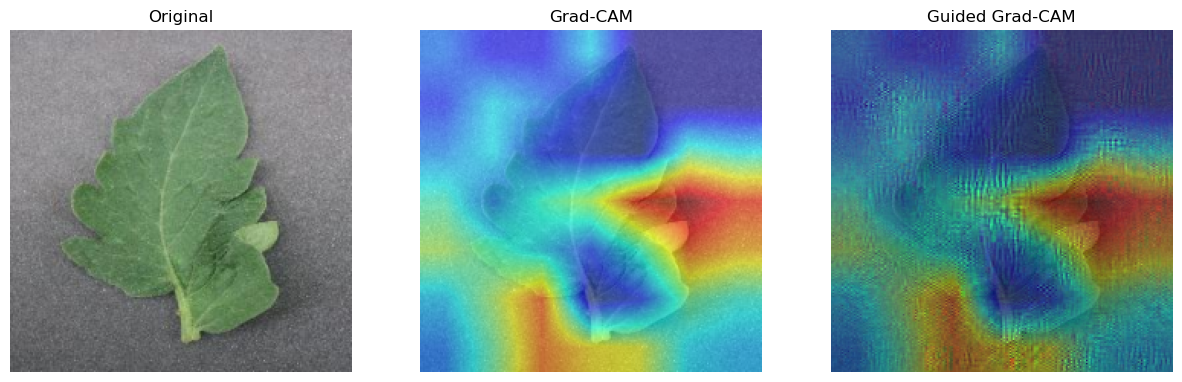

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(rgb_img)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(cam_image)
plt.title("Grad-CAM")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(guided_gradcam)
plt.title("Guided Grad-CAM")
plt.axis("off")

plt.savefig(RESULTS_DIR / "guided_gradcam.png", bbox_inches="tight")
plt.show()


## 9. Final Sample Prediction


Actual: Pepper__bell___Bacterial_spot
Predicted: Pepper__bell___Bacterial_spot


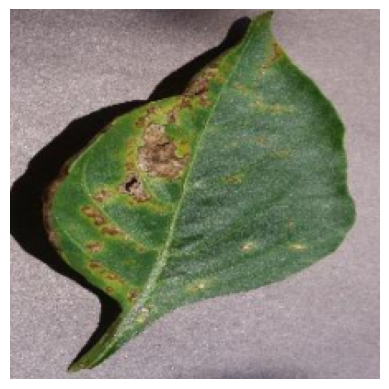

In [59]:
best_model.eval()

image, label = dataset[0]

input_tensor = image.unsqueeze(0).to(device)

with torch.no_grad():
    output = best_model(input_tensor)
    predicted_class = torch.argmax(output, dim=1).item()

display_img = image.permute(1,2,0).cpu().numpy()
display_img = (display_img * 0.5) + 0.5
display_img = display_img.clip(0, 1)

plt.imshow(display_img)
plt.axis("off")

plt.savefig(RESULTS_DIR / "sample_prediction.png", bbox_inches="tight")
print("Actual:", dataset.classes[label])
print("Predicted:", dataset.classes[predicted_class])
